# Exact versus approximate inverse QFT in phase estimation

The output task is a **scalar median phase estimate**, rather than a Fourier-state measurement with no inference contract. The prepared phase is 0.3, target width one, requested absolute phase error 2⁻ᵐ and whole-run failure target 1%. Every complete trial has fresh preparation, all repeated controlled-U calls, retained inverse-QFT gates and final phase measurements.

The predeclared physical comparison uses m=5,6,7, exact cutoff m−1 versus one omitted longest-distance phase m−2, synthesis-model allowances 10⁻⁴/10⁻⁵ and two frozen physical profiles. Known-phase preparation makes this a correctness/resource example, without an application-speedup claim.

In [1]:
from pathlib import Path
import sys, os, math, csv, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, SVG
root=Path.cwd()
if not (root/"src").exists() and (root.parent/"src").exists():
    root=root.parent
if (root/"src").exists():sys.path.insert(0,str(root/"src"))
from openquantum.approximate_qft_resources import (
    QPEVariantContract, build_contract_trial, checked_distribution,
    fixed_grid, majority_failure_upper,
)
from openquantum.qft_qpe import qpe_distribution
from openquantum.resource_estimation import prepare_measured_circuit
output=root/"assets/generated/qft-variant-comparison"
selected=QPEVariantContract(5,3,synthesis_model_allowance_per_trial=1e-5)
source=build_contract_trial(selected,measure=True)
compiled=prepare_measured_circuit(source)
print({"phase":selected.phase,"phase_error_target":selected.phase_error_target,
       "cutoff":selected.max_distance,"fresh_trials":selected.repetitions,
       "omission_output_tv_upper":float(selected.omission_output_tv_upper),
       "synthesis_model_allowance_per_trial":selected.synthesis_model_allowance_per_trial,
       "statistical_failure_allowance":float(selected.statistical_failure_allowance),
       "physical_failure_allowance_all_trials":selected.physical_failure_allowance})

{'phase': 0.3, 'phase_error_target': 0.03125, 'cutoff': 3, 'fresh_trials': 127, 'omission_output_tv_upper': 0.19642857142857142, 'synthesis_model_allowance_per_trial': 1e-05, 'statistical_failure_allowance': 0.0049, 'physical_failure_allowance_all_trials': 0.005}


## Actual complete truncated trial

The cutoff keeps every Hadamard and final swap. Only the longest-distance inverse-QFT controlled phase is omitted. The phase-gate U is implemented and repeated 2ᵐ−1 times; powers are not free oracles.

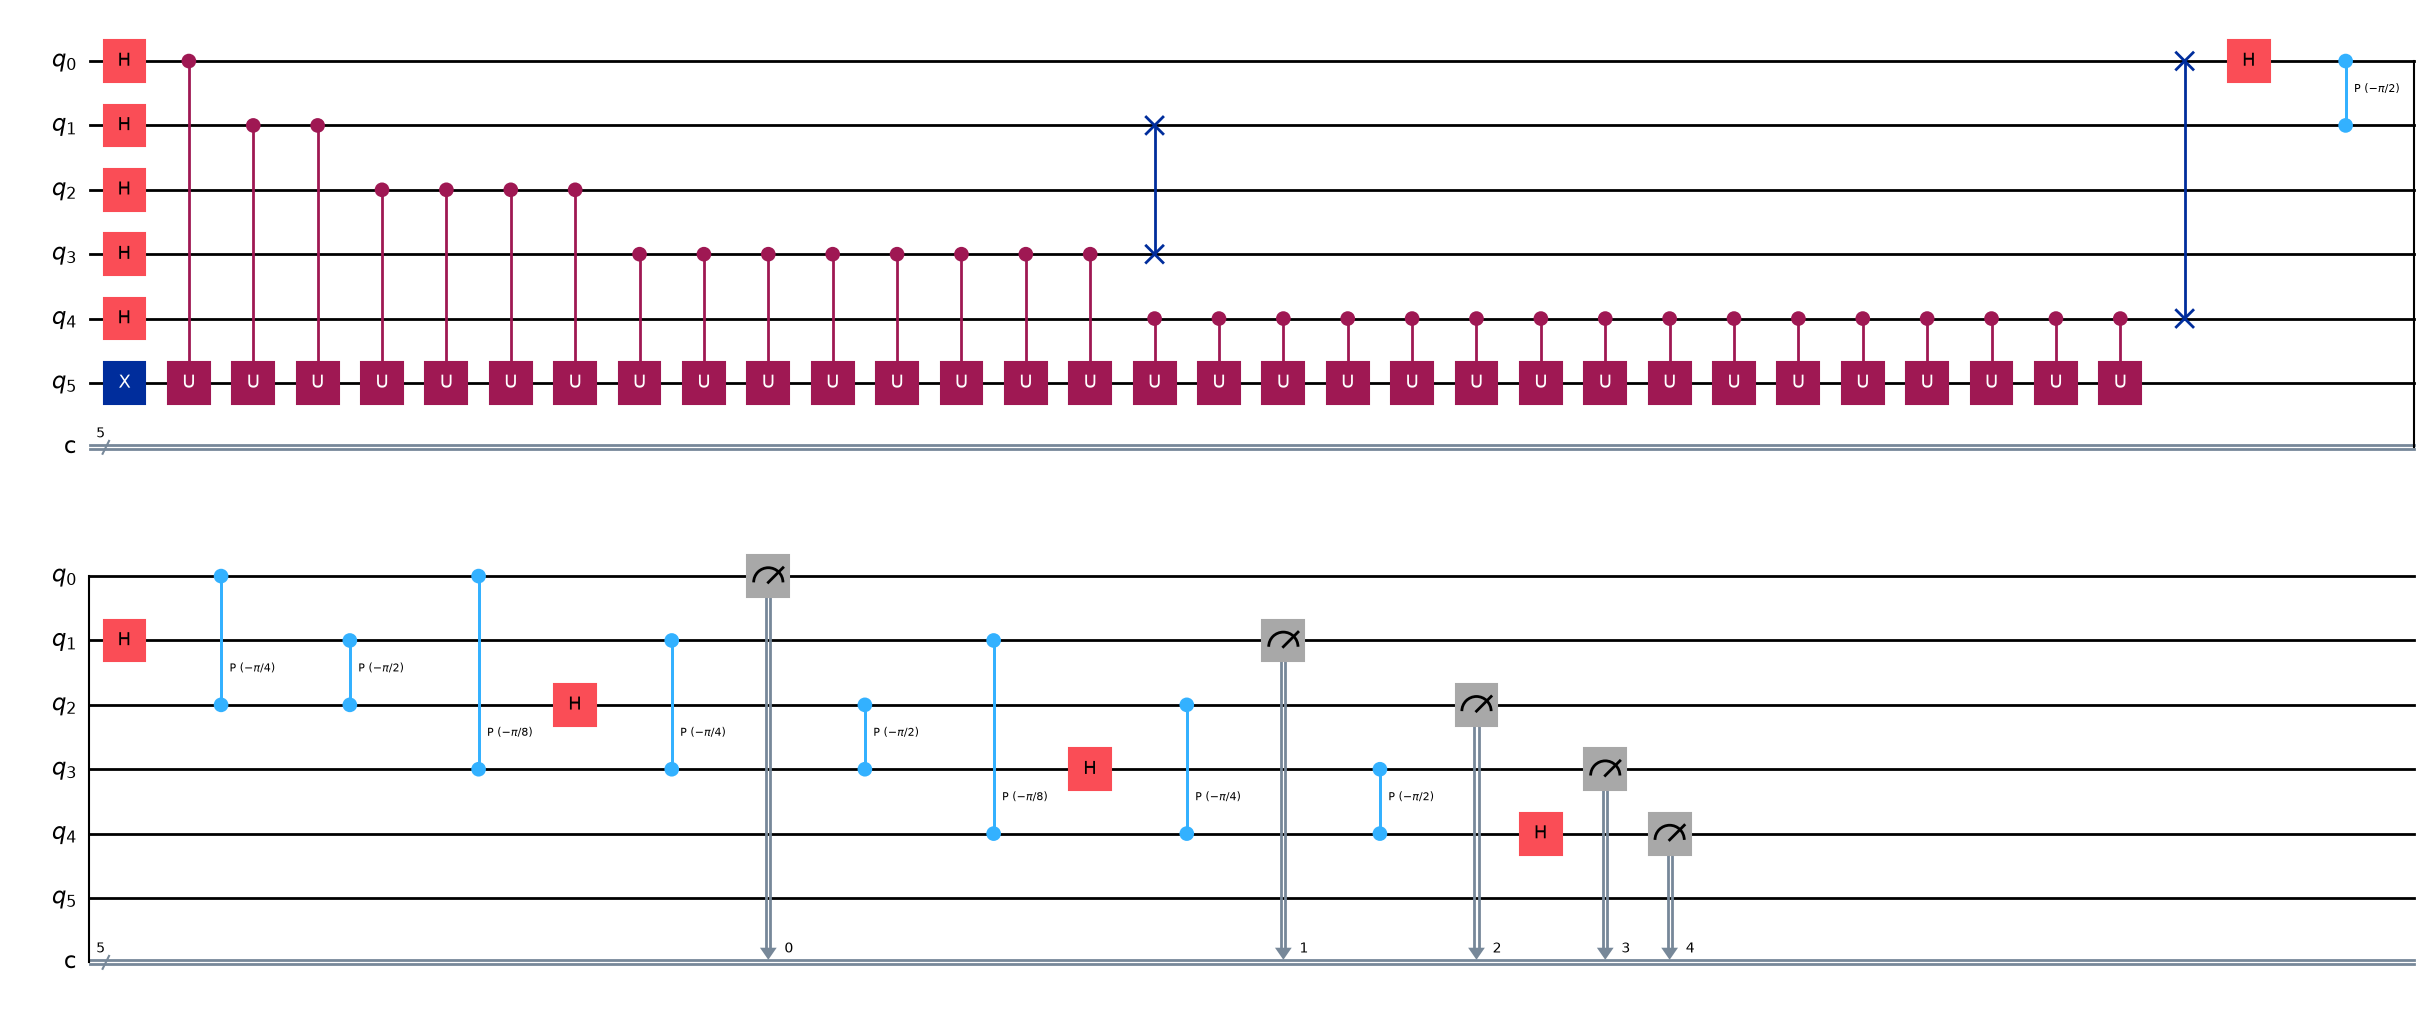

In [2]:
display(source.draw(output="mpl",fold=36,style="iqp"))
plt.close("all")

## Omission and confidence have different units

The ideal spectral omission bound η controls worst-case output-distribution total variation. It changes a bound on **single-trial bad-output probability**, not the numerical phase tolerance. The conservative allocation uses π<22/7: base bad probability is at most 23/121, plus rational dyadic omission bound plus the synthesis-TV model allowance.

Exact Fraction binomial tails select the least odd number of fresh trials whose majority failure is at most 0.0049. Physical faults use a separate 0.005 whole-run allowance. The same requested error 2⁻ᵐ remains in each exact/truncated pair. Hardware confidence, binary64 phase enclosures and concrete synthesis/runtime tails are not certified.

In [3]:
rows=[]
for m in [5,6,7]:
    for cutoff in [m-1,m-2]:
        contract=QPEVariantContract(m,cutoff,synthesis_model_allowance_per_trial=1e-5)
        trial=build_contract_trial(contract)
        actual=checked_distribution(trial,m)
        exact=qpe_distribution(.3,m)
        tv=.5*float(np.abs(actual-exact).sum())
        assert tv<=float(contract.omission_output_tv_upper)+3e-12
        if cutoff==m-1:assert np.max(np.abs(actual-exact))<3e-12
        measured=build_contract_trial(contract,measure=True)
        primitive=prepare_measured_circuit(measured)
        count=sum(value for name,value in primitive.count_ops().items() if name!="barrier")
        tail=majority_failure_upper(contract.single_trial_failure_upper,contract.repetitions)
        assert tail<=contract.statistical_failure_allowance
        rows.append({"m":m,"variant":"exact" if cutoff==m-1 else "truncated",
                     "phase_error_target":contract.phase_error_target,
                     "observed_output_TV":tv,"omission_TV_upper":float(contract.omission_output_tv_upper),
                     "fresh_trials":contract.repetitions,"operations_per_trial":count,
                     "operations_all_trials":count*contract.repetitions,
                     "all_controlled_U_calls":(2**m-1)*contract.repetitions,
                     "all_input_preparations":contract.repetitions,"all_phase_readouts":m*contract.repetitions,
                     "majority_failure_upper":float(tail)})
display(rows)

[{'m': 5,
  'variant': 'exact',
  'phase_error_target': 0.03125,
  'observed_output_TV': 2.083511314865394e-15,
  'omission_TV_upper': 0.0,
  'fresh_trials': 15,
  'operations_per_trial': 227,
  'operations_all_trials': 3405,
  'all_controlled_U_calls': 465,
  'all_input_preparations': 15,
  'all_phase_readouts': 75,
  'majority_failure_upper': 0.0030376981264813095},
 {'m': 5,
  'variant': 'truncated',
  'phase_error_target': 0.03125,
  'observed_output_TV': 0.009072406528621704,
  'omission_TV_upper': 0.19642857142857142,
  'fresh_trials': 127,
  'operations_per_trial': 222,
  'operations_all_trials': 28194,
  'all_controlled_U_calls': 3937,
  'all_input_preparations': 127,
  'all_phase_readouts': 635,
  'majority_failure_upper': 0.004706214175002209},
 {'m': 6,
  'variant': 'exact',
  'phase_error_target': 0.015625,
  'observed_output_TV': 2.404591011983398e-15,
  'omission_TV_upper': 0.0,
  'fresh_trials': 15,
  'operations_per_trial': 418,
  'operations_all_trials': 6270,
  'all_c

At the declared phase, observed output-TV deviations are much smaller than the uniform omission bounds. Omitting a gate can even slightly improve this selected phase's good-output mass. These diagnostics do **not** select repetition counts or replace the conservative predeclared policy.

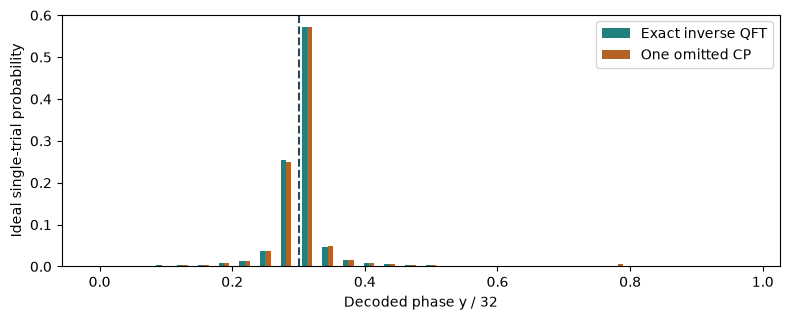

In [4]:
exact_contract=QPEVariantContract(5,4)
approximate_contract=QPEVariantContract(5,3)
exact=checked_distribution(build_contract_trial(exact_contract),5)
approximate=checked_distribution(build_contract_trial(approximate_contract),5)
labels=np.arange(32)/32
fig,axis=plt.subplots(figsize=(8,3.3))
axis.bar(labels-.004,exact,width=.008,label="Exact inverse QFT",color="#1f807e")
axis.bar(labels+.004,approximate,width=.008,label="One omitted CP",color="#b56325")
axis.axvline(.3,ls="--",color="#29485b")
axis.set(xlabel="Decoded phase y / 32",ylabel="Ideal single-trial probability")
axis.legend();fig.tight_layout();display(fig);plt.close(fig)

## Conditional physical comparison

The separate generator estimates every complete measured trial and charges all fresh trials. Both hardware profiles keep 100 ns gates and 500 ns measurements, at physical errors 10⁻³/10⁻⁴. Synthesis allowances remain per output; physical faults are divided over the full repetition count.

The saved figure chooses the fastest returned points. All Pareto points are retained. Peak qubits times total serial runtime is a rectangular proxy, not occupancy integration. Physical initialization/reset, external loading and classical median/controller/decoder/verification latency are excluded.

[{'phase_bits': '5',
  'phase_error_target': '0.03125',
  'phase': '0.3',
  'synthesis_allowance': '0.0001',
  'physical_error_rate': '0.001',
  'total_failure_target': '0.01',
  'exact_trials': '15',
  'truncated_trials': '127',
  'exact_peak_qubits_at_fastest': '249380',
  'truncated_peak_qubits_at_fastest': '647860',
  'exact_fastest_serial_ms': '255.83999999999997',
  'truncated_fastest_serial_ms': '2493.645',
  'truncated_over_exact_fastest_runtime_ratio': '9.746892589118199',
  'exact_peak_qubit_time_product': '63801.3792',
  'truncated_peak_qubit_time_product': '1615532.8497000001',
  'truncated_over_exact_peak_qubit_time_ratio': '25.32128411575153'},
 {'phase_bits': '5',
  'phase_error_target': '0.03125',
  'phase': '0.3',
  'synthesis_allowance': '0.0001',
  'physical_error_rate': '0.0001',
  'total_failure_target': '0.01',
  'exact_trials': '15',
  'truncated_trials': '127',
  'exact_peak_qubits_at_fastest': '36860',
  'truncated_peak_qubits_at_fastest': '36860',
  'exact_fas

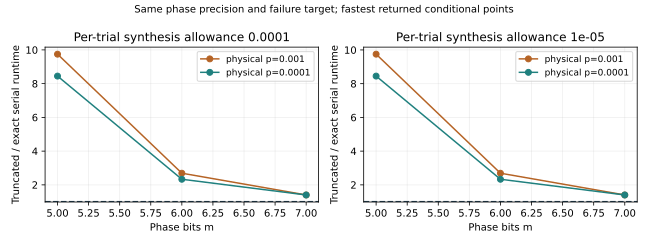

In [5]:
if (output/"matched-comparison.csv").exists():
    with (output/"matched-comparison.csv").open() as handle:
        comparisons=list(csv.DictReader(handle))
    display(comparisons)
    display(SVG(data=(output/"physical-comparison.svg").read_text()))
else:
    print("Run the fixed-grid generator with --estimate for optional conditional physical results.")

The computed predeclared grid saves five primitive operations per trial after lowering. The conservative omission allowance needs 127/35/21 fresh trials at m=5/6/7, compared with 15 exact trials. Here the added trials outweigh the gate saving. This scoped result does not rule out improvement under a sharper independently established application-specific omission/inference contract.

## Optional bounded live controls

Controls regenerate actual circuits and check the omission-TV bound. The saved physical reports apply only to the predeclared phase 0.3; changing the phase below does not reuse those estimates. Static reading requires no kernel backend.

In [6]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    def explore(m=5,phase=.3):
        exact_contract=QPEVariantContract(m,m-1,phase=phase)
        truncated_contract=QPEVariantContract(m,m-2,phase=phase)
        a=checked_distribution(build_contract_trial(exact_contract),m)
        b=checked_distribution(build_contract_trial(truncated_contract),m)
        tv=.5*float(np.abs(a-b).sum())
        assert tv<=float(truncated_contract.omission_output_tv_upper)+3e-12
        print({"phase":phase,"m":m,"observed_output_TV":tv,
               "omission_TV_upper":float(truncated_contract.omission_output_tv_upper),
               "exact_trials":exact_contract.repetitions,"truncated_trials":truncated_contract.repetitions,
               "physical_results_reused":False})
    widgets.interact(explore,m=widgets.Dropdown(options=[5,6,7],value=5),
                     phase=widgets.Dropdown(options=[.125,.3,.5,.7,.875],value=.3))
else:
    print("Saved bounded outputs; launch a live kernel for controls.")

Saved bounded outputs; launch a live kernel for controls.


## Reproduce and inspect

Use Python 3.12 and the locked environment from the public source package:

```bash
python scripts/generate_qft_variant_comparison.py --estimate
python -m pytest tests/test_approximate_qft_resources.py
```

Qiskit core constructs and simulates actual gates; NumPy supplies independent reference arithmetic; Matplotlib supplies original figures. The spectral omission construction follows the approximate-QFT framework cited by the parent chapter. No Lean proof or certified hardware implementation is integrated.